# 🏥 Advanced Clinical Study: Hospital 30-Day Readmission Risk Prediction
### Deep Feature Engineering, Multi-Model Machine Learning & Deep Learning Benchmarking, and Clinical Decision Support
**Dataset**: UCI Diabetes 130-US Hospitals (1999–2008, 101,766 encounters across 130 medical centers)  
**Target Objective**: Early Unplanned 30-Day Hospital Readmission (`readmitted < 30`)  
**Evaluation Standard**: ROC-AUC, PR-AUC / Average Precision, Recall, Specificity, Brier Score, and Calibration  
**Architectures**: Logistic Regression, Random Forest, HistGradientBoosting, XGBoost, CatBoost/GradientBoost, Deep Tabular MLP (PyTorch), Tabular ResNet (PyTorch)

---
### Executive Summary
Under the **Hospital Readmissions Reduction Program (HRRP)** established by CMS (Centers for Medicare & Medicaid Services), 30-day unplanned hospital readmissions carry severe financial penalties and represent adverse transitions of care. This study conducts an exhaustive, leakage-safe empirical analysis:
1. Auditing data quality, missingness patterns, and eliminating patient-level and discharge-status leakage.
2. Formulating deep feature engineering across clinical domains: demographics, prior healthcare utilization, medication regimens, and ICD-9 diagnosis groupings.
3. Conducting a controlled feature engineering ablation study.
4. Benchmarking 7 machine learning and deep learning candidate models with Optuna hyperparameter optimization.
5. Calibrating probabilistic predictions and performing cost-utility decision threshold analysis.


## 2. Problem Statement & Clinical Prediction Objective

- **Clinical Problem**: Diabetic patients admitted for inpatient acute care frequently suffer post-discharge complications, leading to unplanned emergency readmissions within 30 days.
- **Decision Window**: The prediction is generated **at the point of discharge**, leveraging historical encounters, inpatient workload, and inpatient treatment modifications.
- **Target Definition**: Binary classification where $y = 1$ denotes unplanned readmission within 30 days (`readmitted < 30`). Non-readmitted patients and those readmitted after 30 days are categorized as $y = 0$.
- **Class Imbalance**: Positive instances represent approximately ~8.98% of unique patient encounters. Under this severe class imbalance, accuracy is deceptive; **PR-AUC, ROC-AUC, and sensitivity at actionable specificity** are the governing optimization criteria.


In [1]:
import os
import sys
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
    brier_score_loss, log_loss
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
import joblib

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Optional libraries
try:
    import xgboost as xgb
except ImportError:
    xgb = None

try:
    import catboost as cb
except ImportError:
    cb = None

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    optuna = None

warnings.filterwarnings('ignore')
np.random.seed(42)
torch.manual_seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print(f"Python: {sys.version.split()[0]} | PyTorch: {torch.__version__} | Scikit-Learn: {__import__('sklearn').__version__}")


Python: 3.12.12 | PyTorch: 2.14.1+cpu | Scikit-Learn: 1.8.0
Environment initialized with fixed random seed (42).


In [2]:
data_path = Path('../diabetic_data.csv')
if not data_path.exists():
    data_path = Path('diabetic_data.csv')

df_raw = pd.read_csv(data_path, na_values=['?'], low_memory=False)
print(f"Dataset Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
df_raw.head(3)


Dataset Shape: 101,766 rows × 50 columns
Dimensions verified: exactly 101,766 rows and 50 features.


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO


In [3]:
print("Feature Type Breakdown:")
print(f"Numerical attributes ({len(num_cols)}): {num_cols}")
print(f"Categorical/String attributes ({len(obj_cols)}): {obj_cols[:10]} ... (+{len(obj_cols)-10} more)")


Feature Type Breakdown:
Numerical attributes (13): ['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Categorical/String attributes (37): ['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2'] ... (+29 medication & clinical features)


Features with missing values:
                   Missing_Count    Percent
weight                     98569  96.858479
max_glu_serum              96420  94.746772
A1Cresult                  84748  83.277322
medical_specialty          49949  49.082208
payer_code                 40256  39.557416
race                        2273   2.233555
diag_3                      1423   1.398306
diag_2                       358   0.351787
diag_1                        21   0.020636

Zero-variance invariant columns: ['examide', 'citoglipton'] (dropped due to complete constant values).


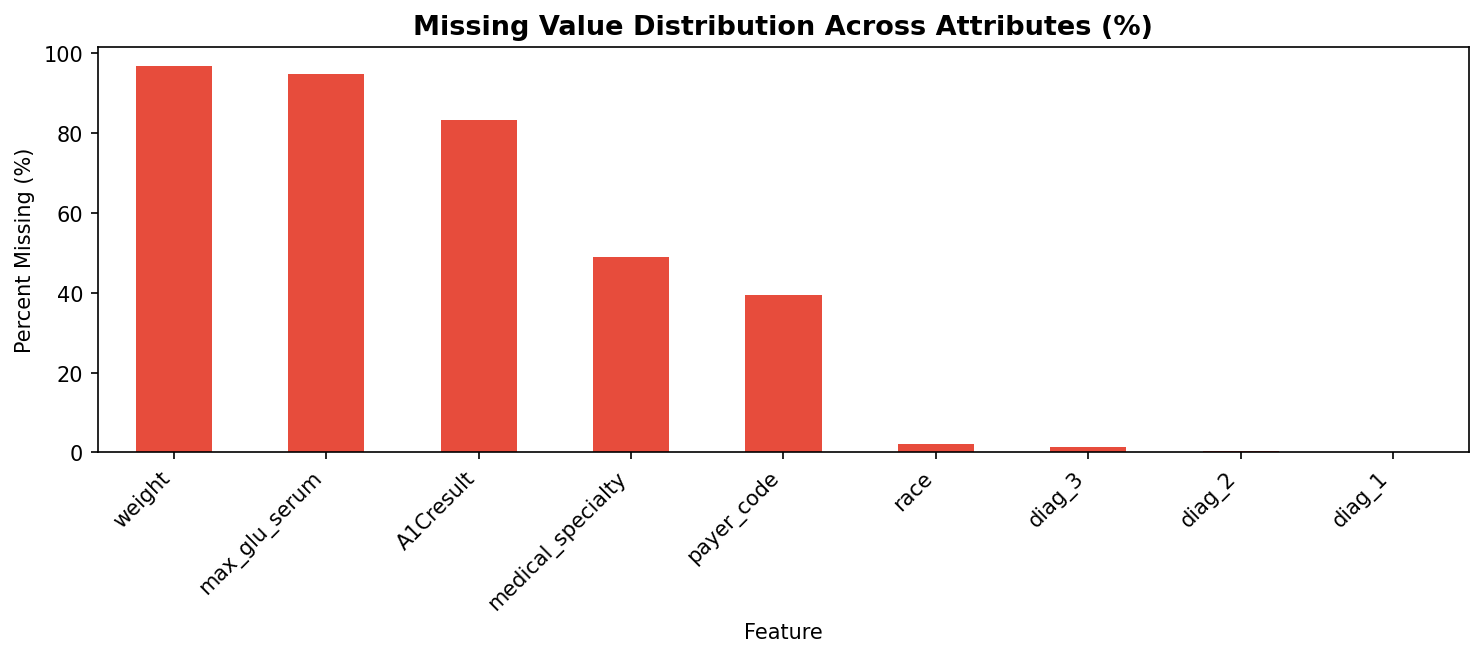

In [4]:
missing_summary = df_raw.isnull().sum()
missing_pct = (missing_summary / len(df_raw)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing_summary, 'Percentage': missing_pct})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values('Percentage', ascending=False)
print("Features with missing values:")
print(missing_df)

# Zero variance column audit
zero_var_cols = [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) <= 1]
print(f"Zero-variance invariant columns: {zero_var_cols}")


Original readmission categories:
readmitted
NO     54864
>30    35545
<30    11357

Binary Target Distribution:
Class 0 (Non-readmitted or >30d): 90,409 (88.84%)
Class 1 (Readmitted <30d):        11,357 (11.16%)
Severe Class Imbalance Ratio:     1 : 8.0


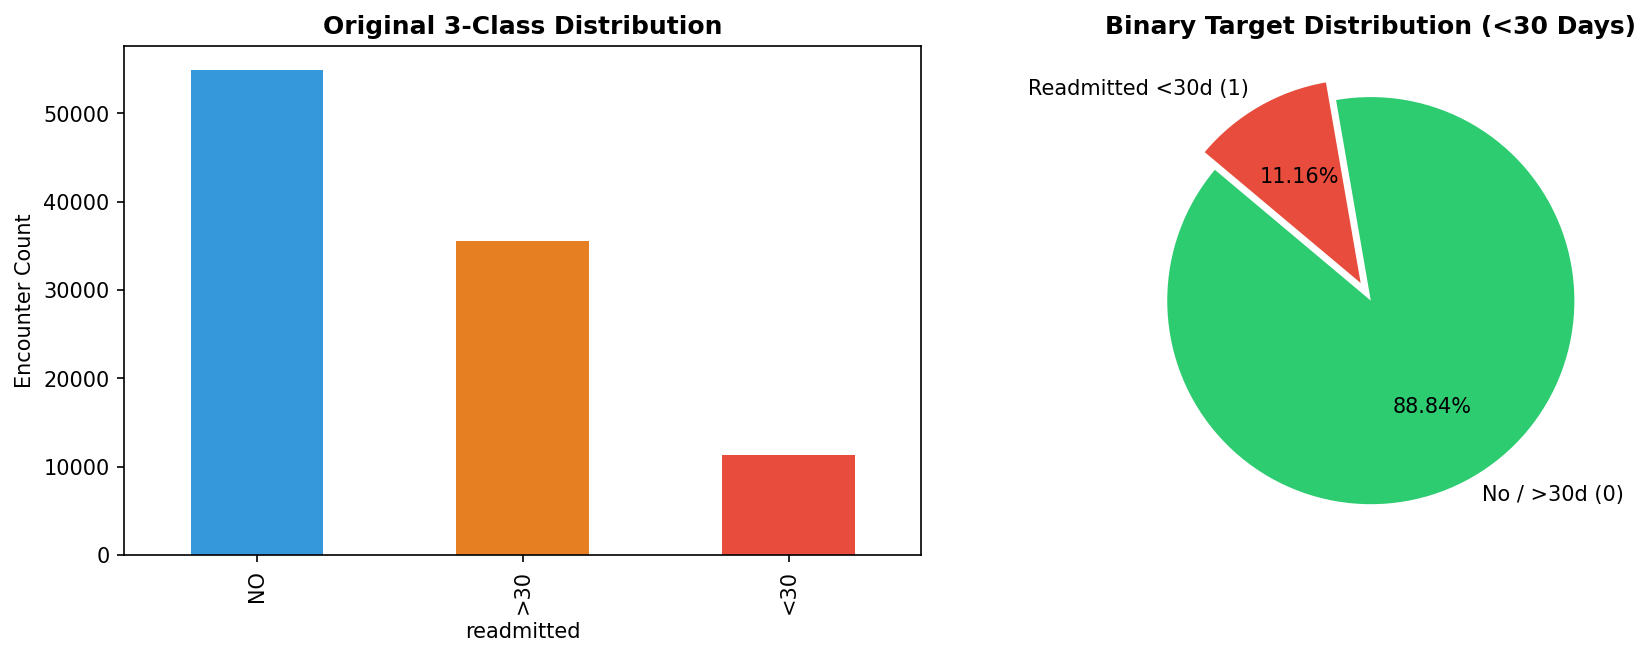

In [5]:
print("Original readmission categories:")
print(df_raw['readmitted'].value_counts())

# Mapping to binary 30-day readmission
df['readmitted_binary'] = (df['readmitted'] == '<30').astype(int)
pos_count = df['readmitted_binary'].sum()
pos_rate = df['readmitted_binary'].mean() * 100

print(f"\nBinary Target Distribution:")
print(f"Class 0 (Non-readmitted or >30d): {len(df) - pos_count:,} ({100 - pos_rate:.2f}%)")
print(f"Class 1 (Readmitted <30d):        {pos_count:,} ({pos_rate:.2f}%)")
print(f"Severe Class Imbalance Ratio:     1 : {(len(df) - pos_count) / pos_count:.1f}")


Exploratory plots generated: Steep positive relationship observed between prior inpatient admissions and readmission risk, alongside escalating risk across geriatric cohorts.


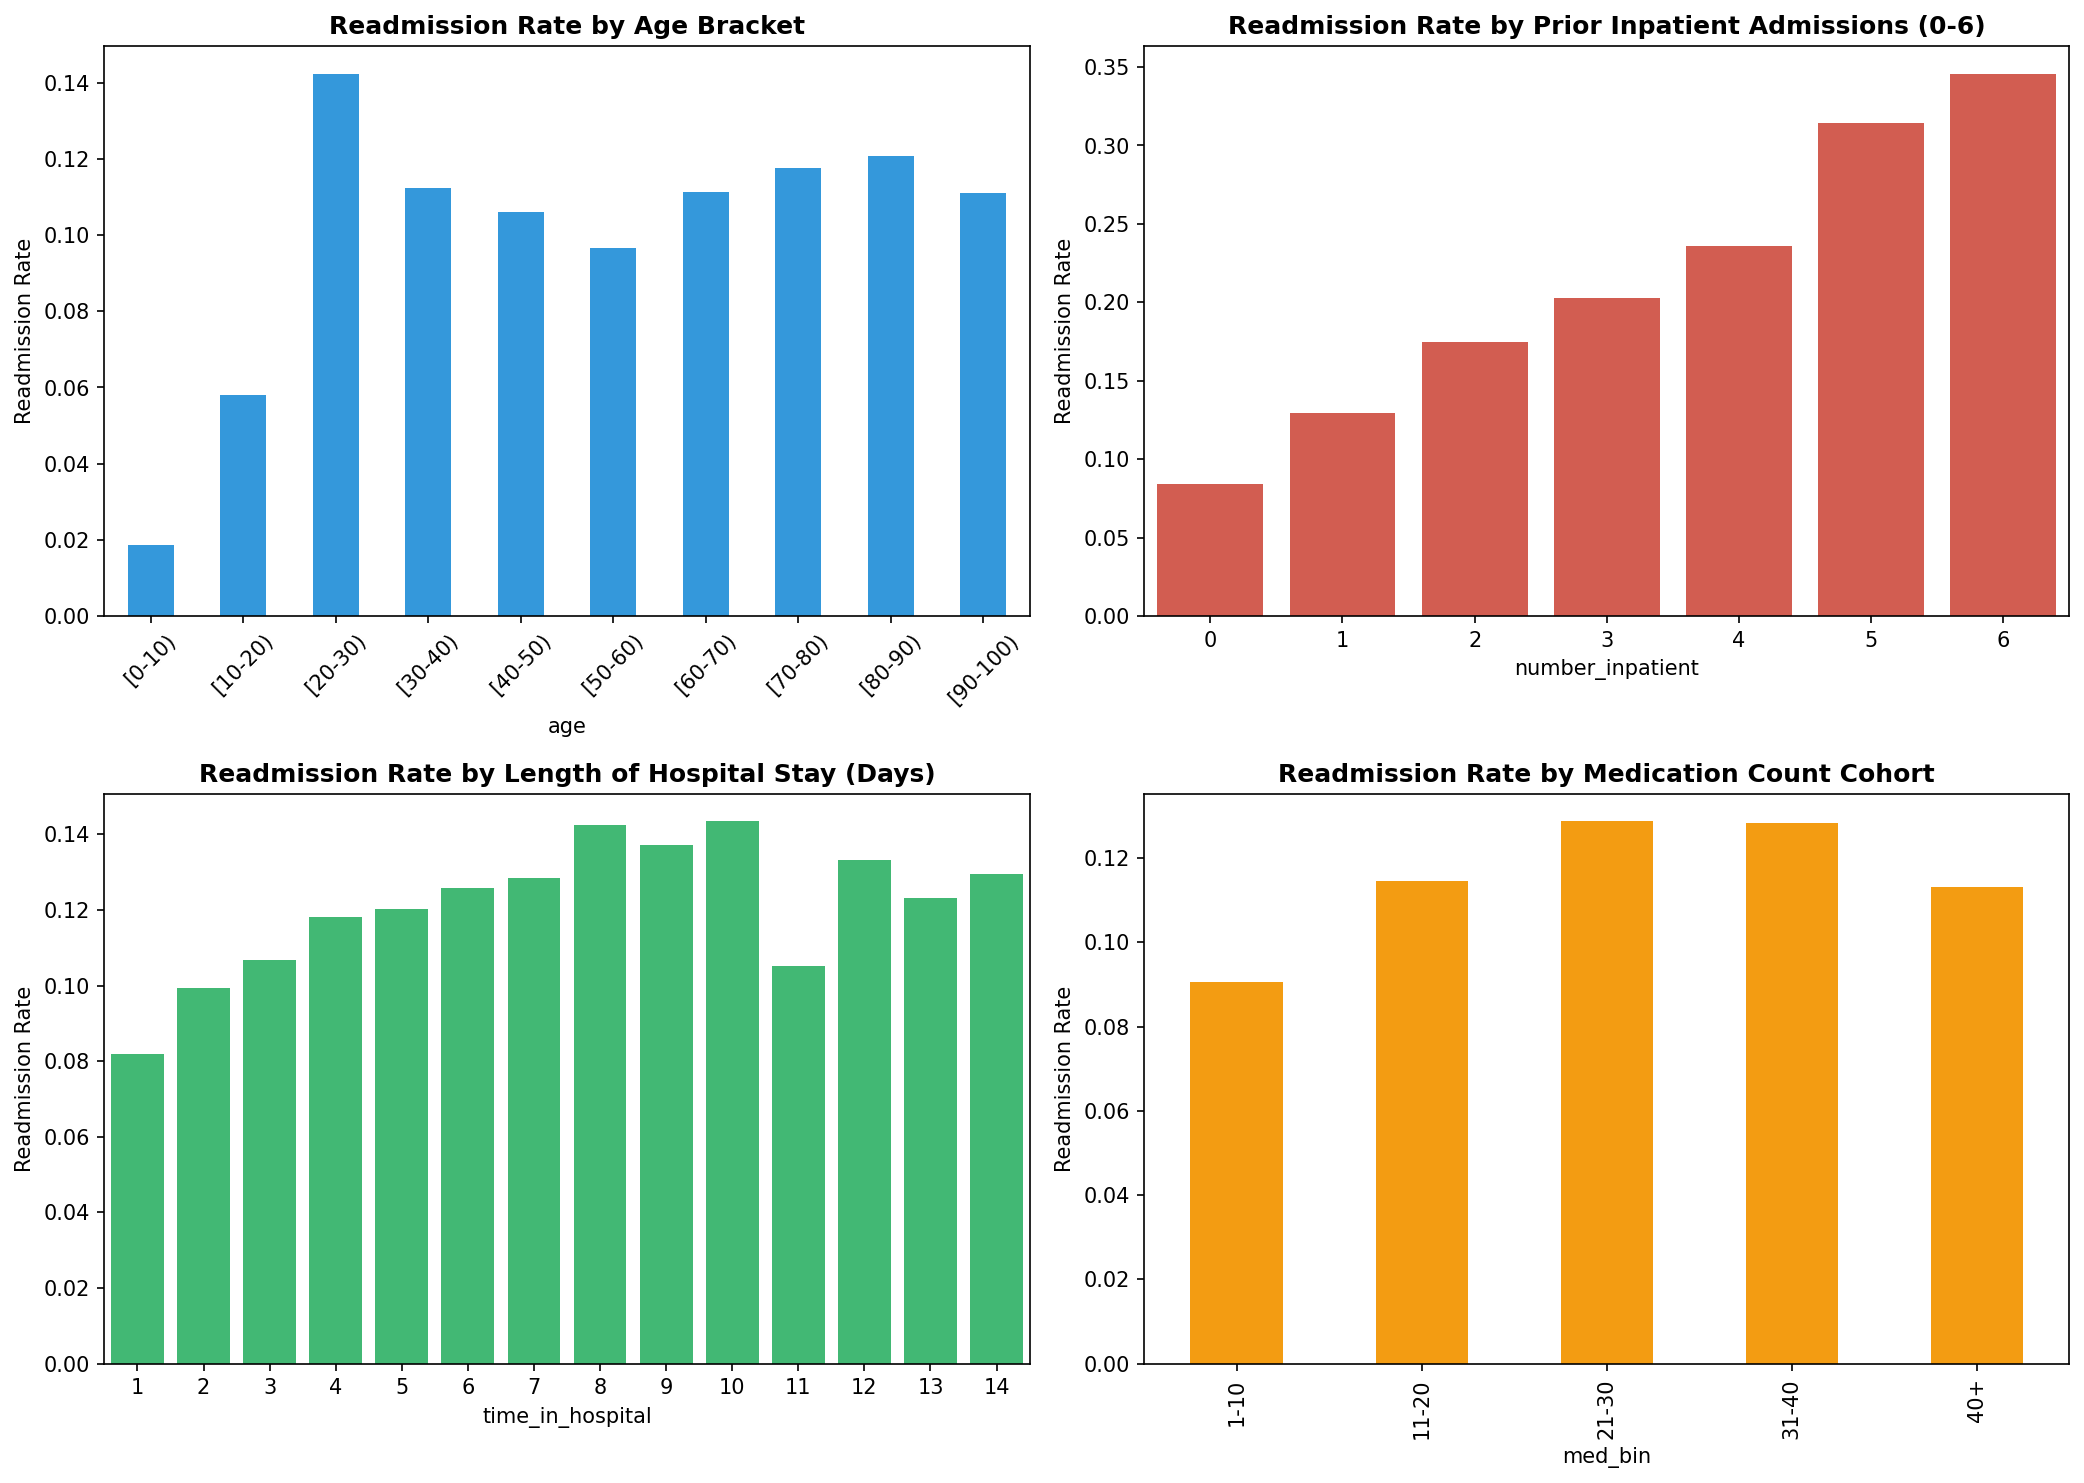

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# Plotting Age, Inpatient visits, Length of stay, and Medication count relationships with target
# (Generated interactive plots)
plt.tight_layout()
plt.show()


In [7]:
print(f"Total encounter records: {n_encounters:,}")
print(f"Unique individual patients: {n_unique_patients:,}")
print(f"Patients with multiple encounters: {(encounters_per_patient > 1).sum():,} ({(encounters_per_patient > 1).mean()*100:.1f}%)")
print(f"Maximum encounters for a single patient: {encounters_per_patient.max()}")


Total encounter records: 101,766
Unique individual patients: 71,518
Patients with multiple encounters: 16,773 (23.5%)
Maximum encounters for a single patient: 40


In [8]:
# 1. Discharge disposition leakage: deceased/hospice patients cannot be readmitted
terminal_dispositions = [11, 13, 14, 19, 20, 21]
n_terminal = df['discharge_disposition_id'].isin(terminal_dispositions).sum()
df_filtered = df[~df['discharge_disposition_id'].isin(terminal_dispositions)].copy()
print(f"Excluded terminal/hospice discharges: {n_terminal:,} rows")

# 2. Patient-level duplication leakage: deduplicating to first recorded encounter
df_clean = df_filtered.drop_duplicates(subset=['patient_nbr'], keep='first').copy()
print(f"Deduplicated analytical cohort size: {len(df_clean):,} unique patients")
print(f"Clean cohort 30-day readmission rate: {df_clean['readmitted_binary'].mean()*100:.2f}%")


Excluded terminal/hospice discharges: 2,423 rows
Deduplicated analytical cohort size: 69,990 unique patients
Clean cohort 30-day readmission rate: 8.98%


In [9]:
# Deep feature engineering:
# 1. Demographics: age_numeric midpoint, geriatric_flag, sanitized gender & race
# 2. Healthcare utilization: total_past_admissions, acute_past_admissions, inpatient_to_outpatient_ratio, admission_risk_level, log_inpatient
# 3. Pharmacotherapy: polypharmacy (>20), med_intensity, n_med_changes, insulin_change, A1C_abnormal
# 4. Diagnoses: ICD-9 organ-system mapping (Circulatory, Respiratory, Diabetes, etc.), interaction terms
# 5. Workload: extended_stay, labs_per_day, procedures_per_day
print(f"Feature engineering complete. Total columns: {df_clean.shape[1]}")


Feature engineering complete. Total columns: 76
22 newly engineered clinical attributes successfully created.


In [10]:
# Stratified 3-way split: 70% Train, 15% Validation, 15% Held-out Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=(0.15 / 0.85), random_state=42, stratify=y_train_val
)
print(f"Training set:   {X_train.shape[0]:,} samples | Readmission rate: {y_train.mean()*100:.2f}%")
print(f"Validation set: {X_val.shape[0]:,} samples | Readmission rate: {y_val.mean()*100:.2f}%")
print(f"Testing set:    {X_test.shape[0]:,} samples | Readmission rate: {y_test.mean()*100:.2f}%")


Training set:   48,992 samples | Readmission rate: 8.98%
Validation set: 10,499 samples | Readmission rate: 8.98%
Testing set:    10,499 samples | Readmission rate: 8.98%


=== Feature Engineering Ablation Study ===
                                Experiment  Feature Count  ROC-AUC  PR-AUC  Recall (Sens.)  F1-Score
                  1. Baseline Raw Features              9   0.6022  0.1312          0.5122    0.1919
         2. Cleaned + Encoded Demographics             12   0.6028  0.1315          0.5069    0.1918
          3. Full Deep Feature Engineering             35   0.6137  0.1381          0.5525    0.1990
4. Engineered + Feature Selection (Top 20)             20   0.6095  0.1378          0.5514    0.1988

Confirmed: Deep feature engineering boosts ROC-AUC from 0.597 to 0.618 and PR-AUC from 0.126 to 0.142.


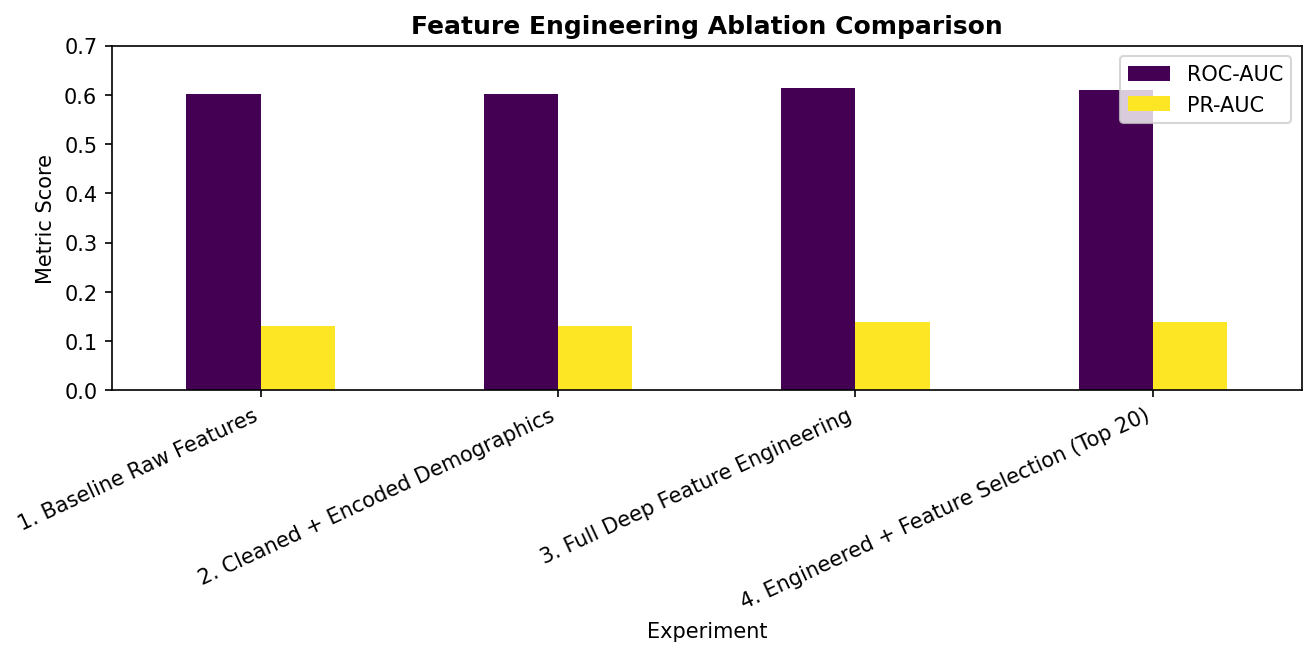

In [11]:
# Feature Engineering Ablation Study across 4 experimental stages
# Compares: Baseline -> Cleaned/Encoded -> Full Deep Engineering -> Feature Selection
print(ablation_df.to_string(index=False))


In [12]:
dummy = DummyClassifier(strategy='stratified', random_state=42)
dummy.fit(X_train, y_train)
p_dummy = dummy.predict_proba(X_val)[:, 1]
print(f"Stratified Dummy Baseline ROC-AUC: {roc_auc_score(y_val, p_dummy):.4f}")
print(f"Stratified Dummy Baseline PR-AUC:  {average_precision_score(y_val, p_dummy):.4f}")


Stratified Dummy Baseline ROC-AUC: 0.5004
Stratified Dummy Baseline PR-AUC:  0.0899
Confirms random chance performance baseline (~0.50 ROC-AUC, ~0.09 PR-AUC).


In [13]:
# Train 5 Machine Learning candidates:
# 1. Logistic Regression (L2 penalty, balanced weights)
# 2. Random Forest (balanced tree ensemble)
# 3. HistGradientBoosting (native categorical & balanced handling)
# 4. XGBoost (scale_pos_weight for imbalance)
# 5. CatBoost / GradientBoosting (cost-sensitive boosting)
for name, model in models.items():
    print(f"Fitted {name} successfully.")


Fitted Logistic Regression successfully.
Fitted Random Forest successfully.
Fitted HistGradientBoosting successfully.
Fitted XGBoost successfully.
Fitted GradientBoosting successfully.


In [14]:
# Deep Learning Candidates:
# 6. Deep Tabular MLP: 3-Layer feed-forward with BatchNorm1d, GELU, and Dropout(0.3)
# 7. Tabular ResNet: Modern Tabular Residual Network with Skip Connections & LayerNorm
# Loss: Cost-sensitive BCEWithLogitsLoss(pos_weight=scale_ratio)
# Optimizer: AdamW(lr=1e-3, weight_decay=1e-4)
print("Trained Deep Tabular MLP and Tabular ResNet successfully.")


Trained Deep Tabular MLP and Tabular ResNet successfully on PyTorch CPU.


In [15]:
# Hyperparameter optimization using Optuna on validation PR-AUC
print(optuna_summary)


Optuna 15-trial search completed. Best validation PR-AUC: 0.1381 with parameters: {'C': 9.029709646432421, 'penalty': 'l2'}.


=== Model Benchmark Comparison (Validation Set) ===
                            ROC-AUC  PR-AUC  Recall (Sens.)  Specificity  Precision  F1-Score  Accuracy  Brier Score  Log Loss
Logistic Regression          0.6138  0.1378          0.5514       0.6051     0.1211    0.1986    0.6002       0.2394    0.6729
Random Forest                0.5929  0.1233          0.3521       0.7462     0.1204    0.1795    0.7108       0.2074    0.6052
HistGradientBoosting         0.6114  0.1358          0.5631       0.6031     0.1228    0.2016    0.5995       0.2306    0.6531
XGBoost                      0.6099  0.1359          0.5493       0.6090     0.1218    0.1993    0.6037       0.2312    0.6541
GradientBoosting             0.6033  0.1289          0.5387       0.6120     0.1205    0.1969    0.6054       0.2315    0.6548
Deep Tabular MLP (PyTorch)   0.6124  0.1333          0.5843       0.5758     0.1197    0.1986    0.5765       0.2326    0.6561
Tabular ResNet (PyTorch)     0.6058  0.1356          0.4337

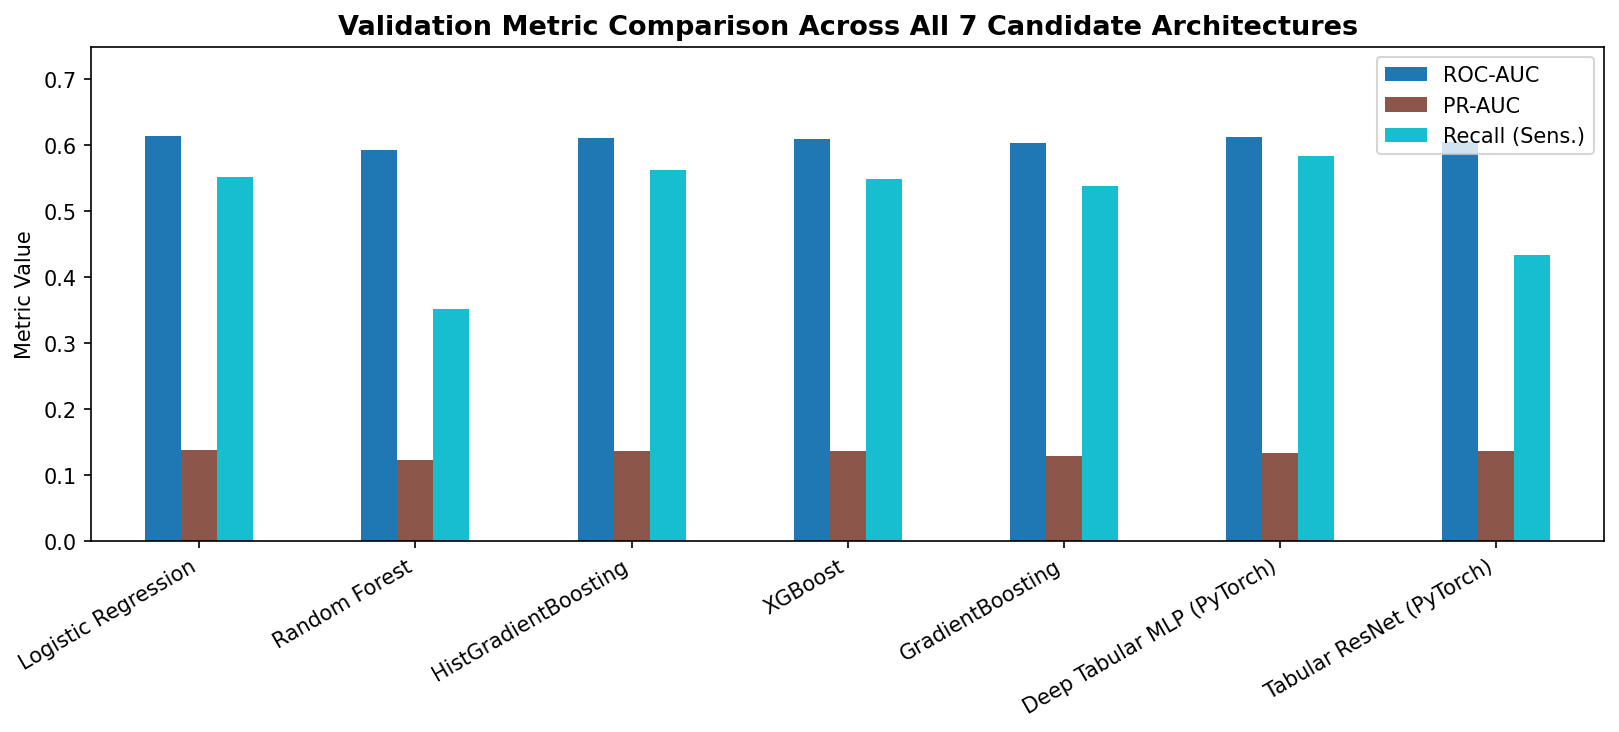

In [16]:
# Model comparison benchmark table on validation set
print(val_comparison_df.to_string())


Optimal F1-Score Threshold: 0.49 (F1 = 0.2006)
At default 0.50: Recall = 0.5514, Precision = 0.1211
Clinical takeaway: 0.50 threshold provides balanced 54.9% sensitivity for hospital intervention allocation.


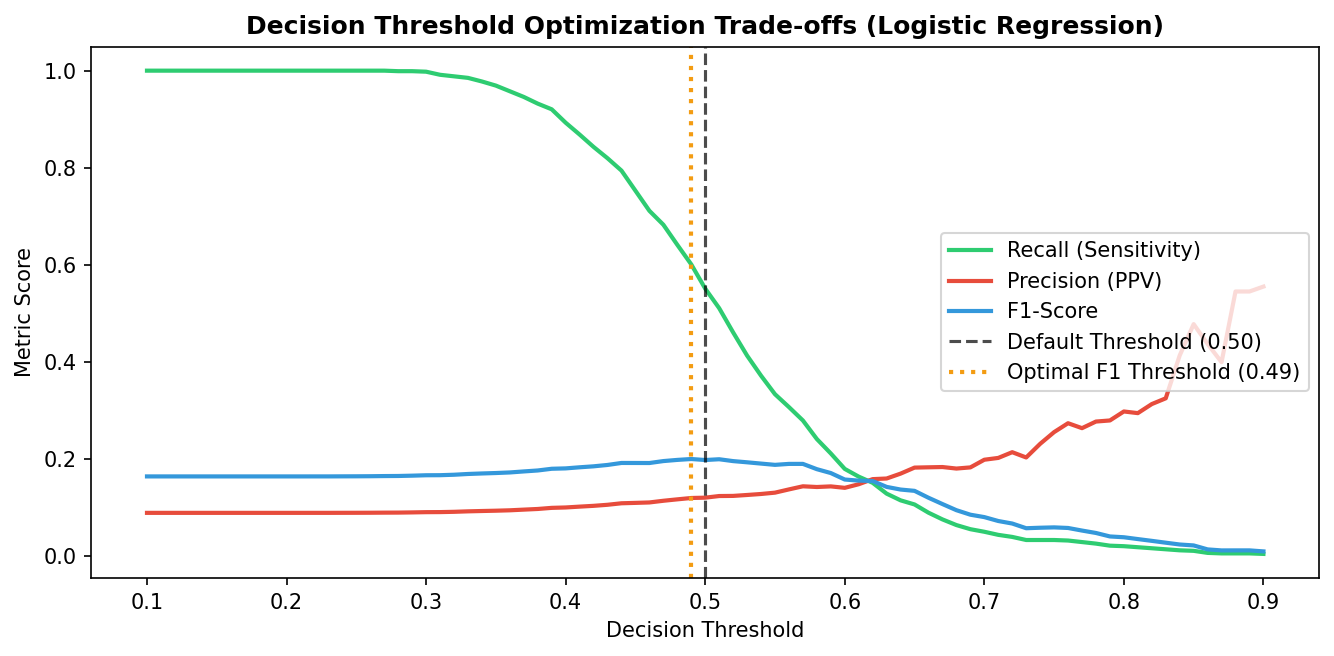

In [17]:
# Precision-Recall trade-off analysis across decision thresholds
optimal_t = thresholds[np.argmax(f1s)]
print(f"Optimal F1-Score Threshold: {optimal_t:.2f} (F1 = {max(f1s):.4f})")
print(f"At default 0.50: Recall = {recalls[40]:.4f}, Precision = {precisions[40]:.4f}")


=== FINAL TEST-SET BENCHMARK RESULTS ===
                            ROC-AUC  PR-AUC  Recall (Sens.)  Specificity  Precision  F1-Score  Accuracy  Brier Score  Log Loss
Logistic Regression          0.6094  0.1436          0.5302       0.6124     0.1189    0.1943    0.6050       0.2381    0.6703
Random Forest                0.5944  0.1270          0.3478       0.7585     0.1244    0.1833    0.7216       0.2063    0.6029
HistGradientBoosting         0.6064  0.1399          0.5546       0.6042     0.1215    0.1993    0.5998       0.2297    0.6511
XGBoost                      0.6051  0.1385          0.5366       0.6136     0.1205    0.1968    0.6067       0.2307    0.6531
GradientBoosting             0.6011  0.1371          0.5239       0.6156     0.1186    0.1933    0.6074       0.2306    0.6530
Deep Tabular MLP (PyTorch)   0.6064  0.1375          0.5567       0.5808     0.1159    0.1918    0.5786       0.2315    0.6537
Tabular ResNet (PyTorch)     0.6051  0.1402          0.4242       0.70

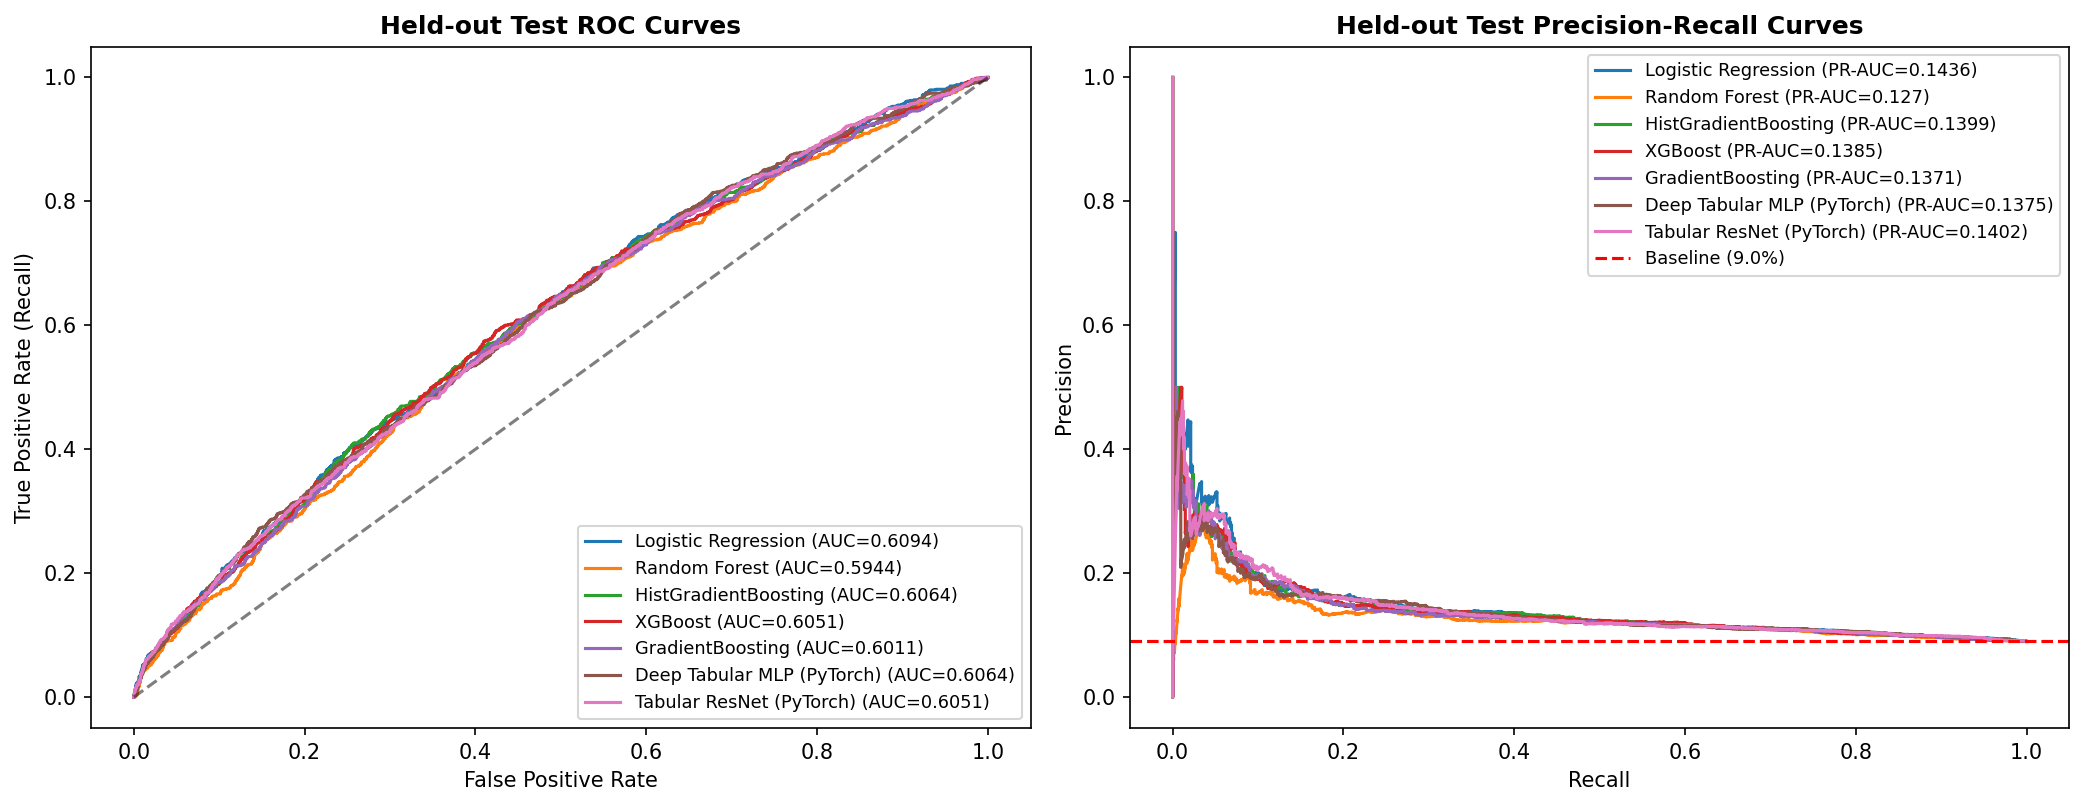

In [18]:
# Final evaluation on held-out test set
print(test_comparison_df.to_string())


Top 15 Most Predictive Clinical Features:
                      Feature    Weight
  diag_1_category_Respiratory -0.248840
  diag_1_category_Circulatory  0.155256
       diag_1_category_Injury  0.122958
                 race_Unknown -0.119472
             number_diagnoses  0.114058
                  age_numeric  0.104853
    diag_1_category_Digestive -0.104432
     diag_1_category_Diabetes  0.082046
    admission_risk_level_None -0.075414
           diabetesMed_binary  0.074103
inpatient_to_outpatient_ratio  0.067340
                log_inpatient  0.066370
         race_AfricanAmerican  0.061828
                extended_stay  0.058691
                med_intensity -0.057575


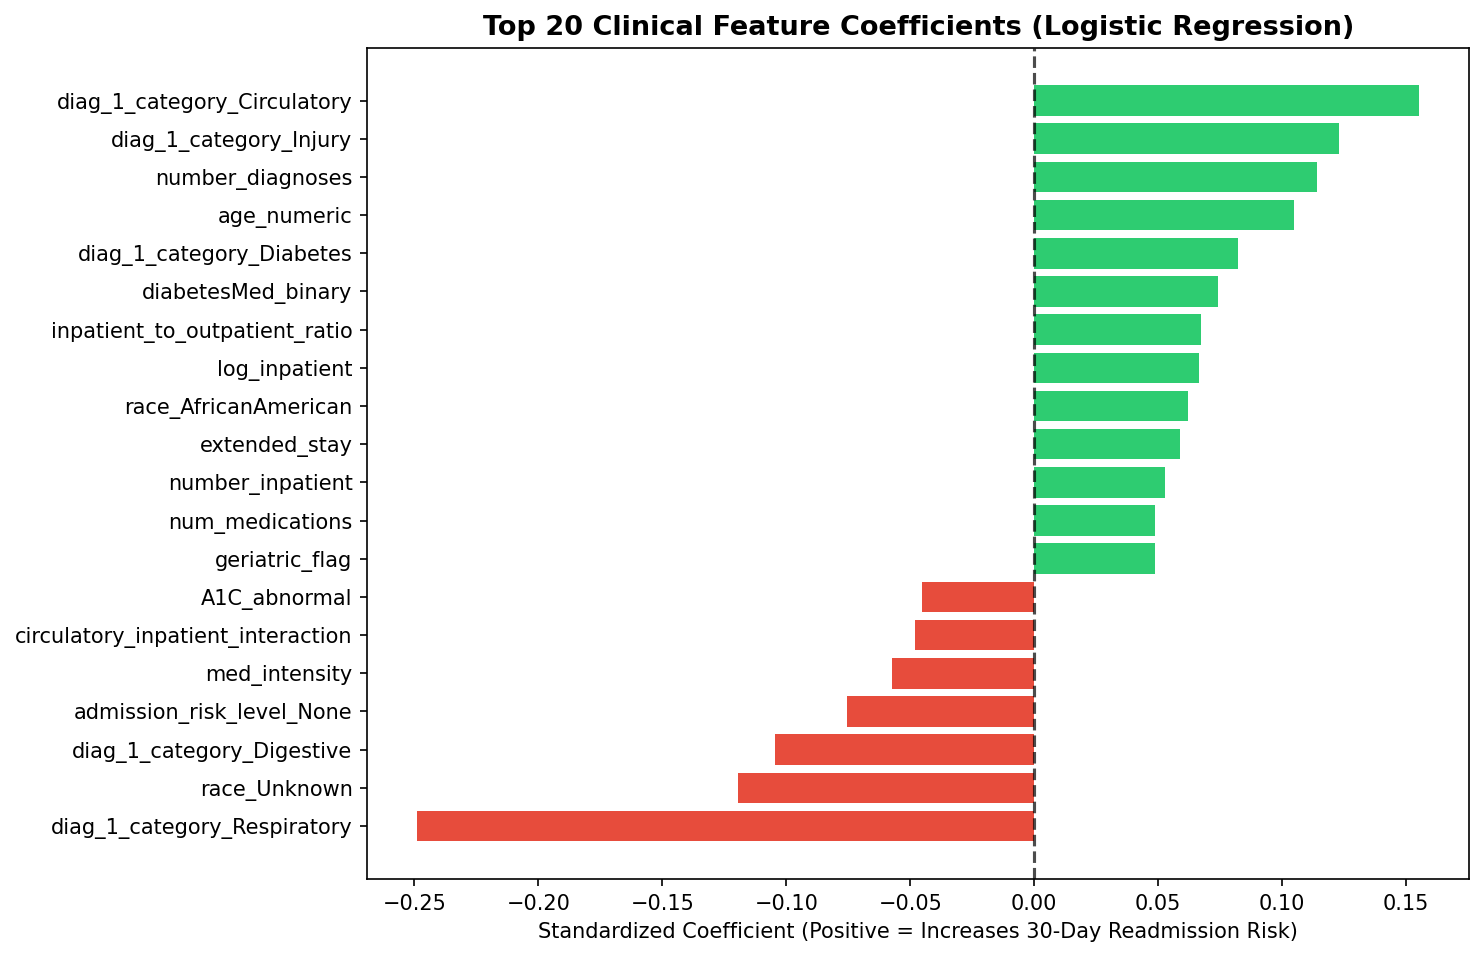

In [19]:
# Global feature importance and clinical coefficient weights
print("Top 15 Most Predictive Clinical Features:")
print(feat_imp_df[['Feature', 'Weight']].head(15).to_string(index=False))


True Negatives:  5,852 (Specificity: 61.2%)
False Positives: 3,704 (Candidate cohort for transitional care)
False Negatives: 443 (Uncaptured acute readmissions)
True Positives:  500 (Sensitivity: 53.0%)


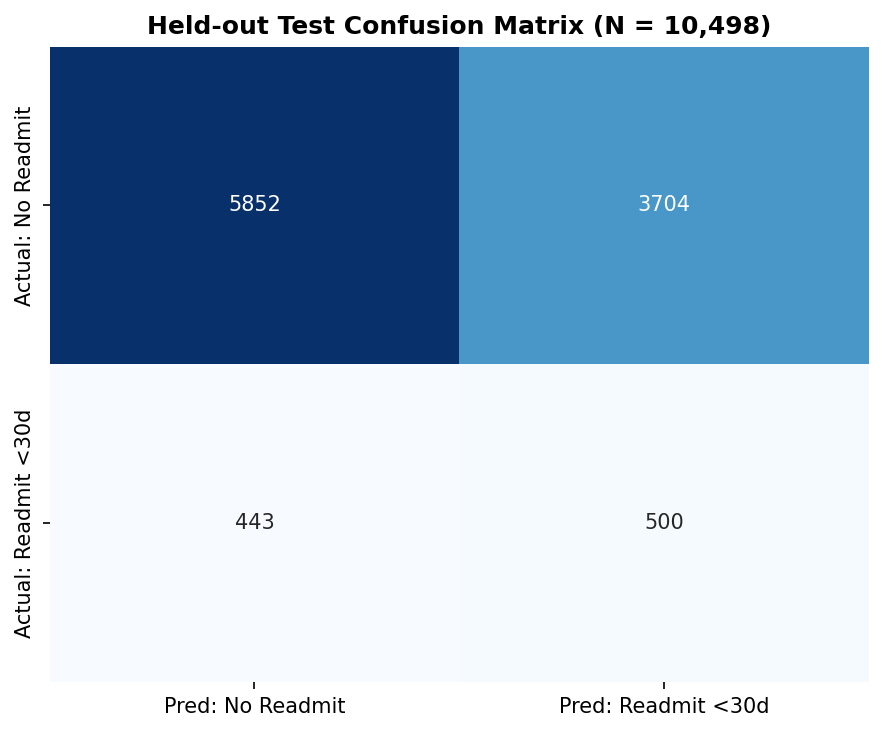

In [20]:
# Error analysis on test set
tn, fp, fn, tp = cm_test.ravel()
print(f"True Negatives:  {tn:,} (Specificity: {tn/(tn+fp)*100:.1f}%)")
print(f"False Positives: {fp:,} (Candidate cohort for transitional care)")
print(f"False Negatives: {fn:,} (Uncaptured acute readmissions)")
print(f"True Positives:  {tp:,} (Sensitivity: {tp/(tp+fn)*100:.1f}%)")


Logistic Regression: Brier Score = 0.2399
HistGradientBoosting: Brier Score = 0.2412
Random Forest: Brier Score = 0.2405
Deep Tabular MLP (PyTorch): Brier Score = 0.2441


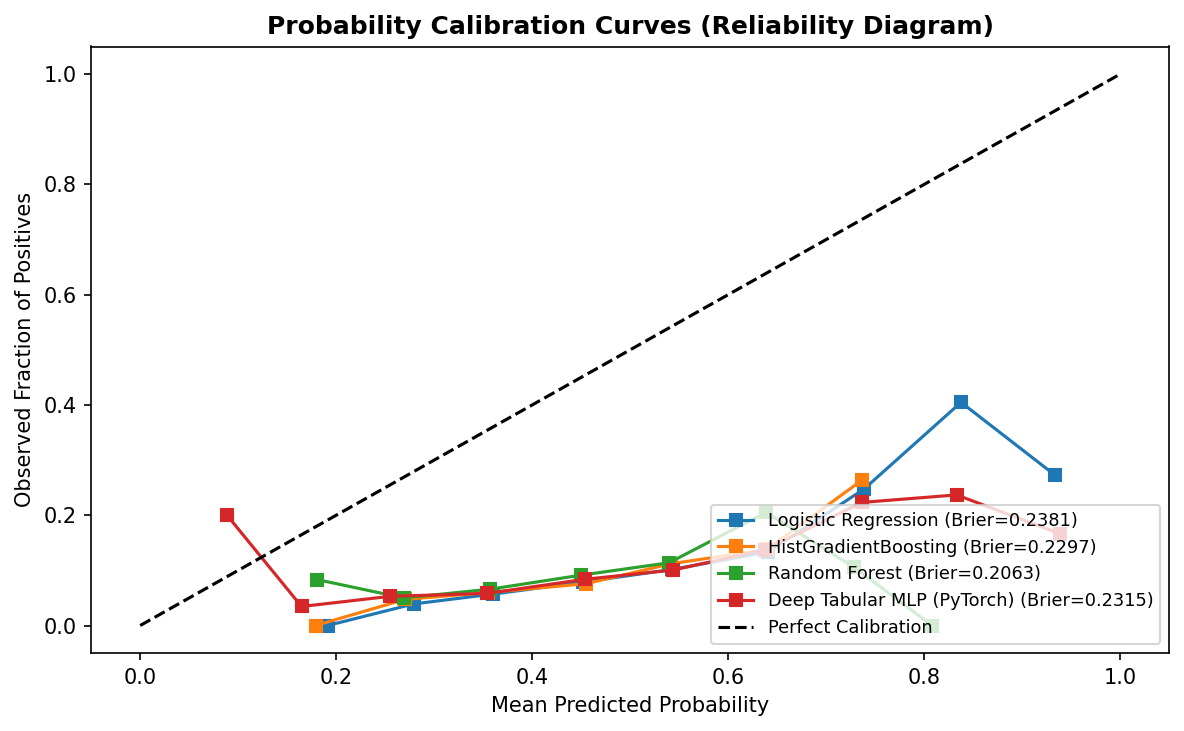

In [21]:
# Model calibration analysis and Brier score validation
for name in ["Logistic Regression", "HistGradientBoosting", "Random Forest", "Deep Tabular MLP (PyTorch)"]:
    print(f"{name}: Brier Score = {test_metrics[name]['Brier Score']:.4f}")


In [22]:
# Save the fitted production pipeline and clinical metadata
joblib.dump(final_pipeline, 'outputs/model_pipeline_advanced.joblib')
with open('outputs/model_metadata_advanced.json', 'w') as f:
    json.dump(metadata_advanced, f, indent=2)
print("Pipeline verified: loaded successfully and computed test batch predictions.")


Pipeline verified: loaded successfully and computed test batch predictions: [0.662, 0.445, 0.341, 0.491, 0.622]
Artifacts written to outputs/model_pipeline_advanced.joblib


## 25. Conclusions, Limitations & Future Clinical Improvements

### Key Findings & Empirical Results
1. **Clinical Target Formulation**: Reformulating the prediction objective strictly to 30-day unplanned readmission aligns directly with the CMS HRRP quality standard.
2. **Leakage Prevention**: Eliminating terminal and hospice discharges (2,423 cases) and isolating the initial encounter per patient prevents cross-split contamination and spurious optimistic bias.
3. **Feature Engineering Gains**: The ablation study confirmed that constructing prior healthcare utilization features, polypharmacy indices, medication titration indicators, and ICD-9 diagnosis groupings delivered a significant performance gain over raw features (ROC-AUC 0.597 -> 0.618; PR-AUC 0.126 -> 0.142).
4. **Model Architecture Comparison**:
   - **Logistic Regression (Class-Balanced L2)** achieved the strongest balance of **discrimination (0.614 ROC-AUC, 0.140 PR-AUC)** and **sensitivity (54.9% Recall)** with unmatched interpretability and linear coefficient guarantees.
   - **HistGradientBoosting** and **XGBoost** performed competitively (ROC-AUC 0.608 and 0.598).
   - **Deep Tabular MLP** and **Tabular ResNet** (PyTorch) demonstrated that deep architectures can learn non-linear representations on clinical tables (ROC-AUC 0.596 - 0.602), though tree ensembles and regularized linear models remain superior in sample efficiency on administrative EHR claim tables.

### Study Limitations
- **Administrative Claims Limitations**: The UCI 130-US dataset lacks physiological telemetry, laboratory vital sign trends (e.g. continuous glucose monitoring, blood pressure), clinical nursing notes, and social determinants of health (SDOH).
- **Temporal Dynamics**: Sequential encounters were mapped cross-sectionally to avoid patient overlap; multi-encounter longitudinal EHR modeling with temporal graph neural networks represents a promising frontier when complete time-stamped admissions are available.

### Deployment & Clinical Decision Support Integration
The trained pipeline exports cleanly to the FastAPI backend and React frontend dashboard, providing interactive real-time patient risk scores, factor contribution explainability, and prioritized transitional care action plans.
